# Реализация полносвязной нейронной сети и сравнение с PyTorch

## 1. Введение  
Целью данной работы является разработка программного инструмента, позволяющего пользователю самостоятельно задавать архитектуру полносвязной нейронной сети, используя для этого простой и гибкий программный интерфейс.  
  
В процессе работы с фреймворком PyTorch у меня возникла идея упростить процесс создания и настройки нейронных сетей, автоматизировав некоторые операции. В рамках данного проекта я решил реализовать собственный подход к построению MLP, который позволил бы сделать процесс построения модели более удобным и интуитивно понятным.  
  
Помимо практической цели, проект также представляет собой попытку разобраться во внутренних механизмах построения и обучения нейронных сетей, реализовав основные компоненты самостоятельно.  

## 2. Основные принципы построения модели в данной реализации    
При разработке инструмента одной из главных идей была возможность гибкой настройки архитектуры полносвязной нейронной сети (MLP). Пользователю должна быть предоставлена возможность самостоятельно определять структуру сети, задавать количество слоёв, количество нейронов в каждом слое, а также выбирать функцию активации для каждого из них.  
  
Отдельное внимание было уделено упрощению процесса конфигурирования модели. В отличие от стандартного подхода в PyTorch, при котором необходимо явно задавать размерности входных и выходных данных для каждого полносвязного слоя, в моей реализации **эти операции выполняются автоматически**.  
  
При создании слоя пользователю достаточно указать желаемое количество нейронов и функцию активации. После определения архитектуры входные данные передаются модели, которая самостоятельно определяет количество входных признаков и рассчитывает необходимые размерности для последующих слоёв, исходя из заданной структуры сети.  
  
Кроме того, автоматизирован процесс формирования связей между слоями. Поскольку каждый нейрон предыдущего слоя связан с каждым нейроном следующего, для представления этих связей используются матрицы весов. Программа самостоятельно определяет размерность каждой такой матрицы на основе количества нейронов в соседних слоях и инициализирует её начальными значениями. Таким образом, пользователю не требуется вручную создавать матрицы весов или определять их размерности.  

Также стоит отметить, что пользователь может самостоятельно выбрать функцию потерь и настроить необходимые гиперпараметры обучения.  
  
Таким образом, основная идея реализации заключается в предоставлении пользователю простого интерфейса для создания и настройки MLP, при котором он самостоятельно определяет архитектуру и основные параметры модели, не тратя время на ручное согласование размерностей отдельных слоёв и другие вспомогательные операции.

## 3. Создание и настройка модели 


Создадим модель полносвязной нейронной сети для распознавания рукописных цифр из набора данных MNIST. Каждое изображение имеет размер 28×28 пикселей и представляется в виде вектора из 784 признаков, значения которых соответствуют интенсивности пикселей. Метки классов представляют собой цифры от 0 до 9. 

Выполним импорт необходимых модулей

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from MLP import *

Подготовим данные для обучения

In [2]:
train_data = np.loadtxt("datasets/mnist_train.csv", delimiter=',', skiprows=1)
test_data = np.loadtxt("datasets/mnist_test.csv", delimiter=',', skiprows=1)
train_data

array([[5., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [4., 0., 0., ..., 0., 0., 0.],
       ...,
       [5., 0., 0., ..., 0., 0., 0.],
       [6., 0., 0., ..., 0., 0., 0.],
       [8., 0., 0., ..., 0., 0., 0.]], shape=(60000, 785))

In [3]:
batch_size = 100

def get_x_y(iteration_numb, data, batch_size):
    beg_idx = batch_size * iteration_numb
    end_idx = beg_idx + batch_size
    batch = data[beg_idx:end_idx]
    y = batch[:, 0].astype(int).reshape(-1, 1)
    x = batch[:, 1:]
    return x, y

In [4]:
x_train, y_train = get_x_y(0, train_data, batch_size)

In [5]:
print(f"Размер батча: {batch_size}")
print(f"Признаки каждого примера батча: {x_train.shape}")
print(f"Метки: {y_train.shape}")

Размер батча: 100
Признаки каждого примера батча: (100, 784)
Метки: (100, 1)


Создадим модель, как объект класса MLP и зададим следующую архитектуру:  
- первый слой содержит 512 нейронов и имеет функцию активации ReLU  
- второй слой содержит 256 нейронов и имеет функцию активации ReLU  
- третий слой содержит 10 нейронов и имеет тождественную функцию активации (Identity)

In [6]:
model = MLP()
model.set_layer(512, "ReLU")
model.set_layer(256, "ReLU")
model.set_layer(10, "Identity")            

Посмотреть текущую архитектуру модели можно с помощью метода *get_settings()*

In [7]:
model.get_settings()

Model is not set!
Layers: 3
0 layer:	512 neurons	Activation func - ReLU
1 layer:	256 neurons	Activation func - ReLU
2 layer:	10 neurons	Activation func - Identity


Для завершения настройки модели необходимо вызвать метод *finish_settings()*, передав ему входные данные. На этом этапе программа определяет количество входных признаков и выполняет инициализацию матриц весов всех слоёв, исходя из заданной архитектуры.

In [8]:
model.finish_settings(x_train) 

Метод *get_weights()* позволяет получить матрицу весов выбранного слоя. Для этого необходимо передать в качестве аргумента индекс интересующего слоя (также, как они описаны при выводе метода *get_settings()*).  
Выведем размеры матрицы весов для каждого из трех слоев.

In [9]:
for i in range(3):
    print(f"Слой: {i} \tРазмер весов: {model.get_weights(i).shape}")

Слой: 0 	Размер весов: (784, 512)
Слой: 1 	Размер весов: (512, 256)
Слой: 2 	Размер весов: (256, 10)


Как можно заметить, размерности матриц весов автоматически определяются на основе количества входных признаков и количества нейронов в соответствующих слоях. Размерность каждой последующей матрицы определяется количеством нейронов предыдущего слоя и текущего слоя. Таким образом, обеспечивается согласованность размерностей при последовательном прохождении данных через сеть.

## 4. Обучение модели

Перед обучением модели требуется указать функцию потерь.  
Для этого необходимо воспользоваться методом *set_loss_function()*, который позволяет задать не только функцию потерь, но и скорость обучения.

In [10]:
lr = 0.01
model.set_loss_function(loss="CrossEntropy", lr=lr)

'CrossEntropy'

Опишем функции для обучения и валидации модели.

In [11]:
min_value = train_data.min()                    # 0
max_value = train_data.max()                    # 255

def train_model(data, batch_size, train_iter, list_of_loss, average_train_iter, average_train_loss):
    data_length = data.shape[0]
    iterations = int(data_length / batch_size)

    for batch in range(iterations):
        train_iter += 1
        x_train, y_train = get_x_y(batch, data, batch_size)
        x_train = (x_train - min_value) / max_value                     # Нормализуем данные
        predict = model.forward(x_train)
        loss = model.Cross_entropy(y_train, predict)
        if batch % 100 == 0:
            print(f"Batch: {batch}\tLoss: {loss}")
            average_train_iter.append(train_iter)
            average_train_loss.append(loss)

        model.backward(x_train, y_train)
        list_of_loss.append(loss)

    return train_iter

def test_model(data, batch_size):
    data_length = data.shape[0]
    iterations = int(data_length / batch_size)
    loss = 0
    pred_true_elems = 0
    all_elems = 0

    for batch in range(iterations):
        x_test, y_test = get_x_y(batch, data, batch_size)
        x_test = (x_test - min_value) / max_value                           # Нормализуем данные
        predict = model.forward(x_test)
        loss += model.Cross_entropy(y_test, predict)

        proba = model.Softmax(predict)                                      # Преобразовываем логиты в вероятности
        labels = np.argmax(proba, axis=1)                                    # Получаем предсказанное значение
        pred_true_elems += np.sum(labels == y_test.ravel())
        all_elems += y_test.shape[0]

    print(f"Test loss: {loss / iterations}")
    print(f"Accuracy: {pred_true_elems / all_elems}\n")

Теперь можно приступать к обучению модели.

In [12]:
epochs = 13
batch_size = 100

# Для анализа изменения ошибки
train_iter = 0
train_loss = list()
average_train_iter = list()
average_train_loss = list()

for i in range(epochs):
    print(f"Epoch: {i}")
    train_iter = train_model(train_data, batch_size, train_iter, train_loss, average_train_iter, average_train_loss)
    test_model(test_data, batch_size)

Epoch: 0
Batch: 0	Loss: 22.933747526220486
Batch: 100	Loss: 4.46050450675975
Batch: 200	Loss: 4.972481695857674
Batch: 300	Loss: 4.677838962555095
Batch: 400	Loss: 2.625744653505085
Batch: 500	Loss: 2.7470858120905746
Test loss: 2.8378677815106736
Accuracy: 0.8864

Epoch: 1
Batch: 0	Loss: 1.6578539640836139
Batch: 100	Loss: 2.376498431867165
Batch: 200	Loss: 3.5038693817521906
Batch: 300	Loss: 2.6123038041007067
Batch: 400	Loss: 2.0693237827060313
Batch: 500	Loss: 2.617216164027833
Test loss: 2.491428814938362
Accuracy: 0.8932

Epoch: 2
Batch: 0	Loss: 1.5210077817479097
Batch: 100	Loss: 2.5970793776052408
Batch: 200	Loss: 2.838092641611775
Batch: 300	Loss: 2.4745814031074262
Batch: 400	Loss: 2.270356411406129
Batch: 500	Loss: 0.8936188589170024
Test loss: 2.216320831151528
Accuracy: 0.9029

Epoch: 3
Batch: 0	Loss: 1.3815525490959315
Batch: 100	Loss: 2.1935697717794396
Batch: 200	Loss: 2.001421750485646
Batch: 300	Loss: 2.430067197194766
Batch: 400	Loss: 1.7024088859952804
Batch: 500	Lo

Полученные результаты демонстрируют, что модель успешно обучается на наборе данных MNIST: значение функции потерь на тестовой выборке постепенно уменьшается, а точность предсказаний возрастает

Построим график зависимости ошибки предсказания модели для каждой итерации.

In [13]:
train_iter

7800

Text(0, 0.5, 'Значение функции потерь (Cross-Entropy)')

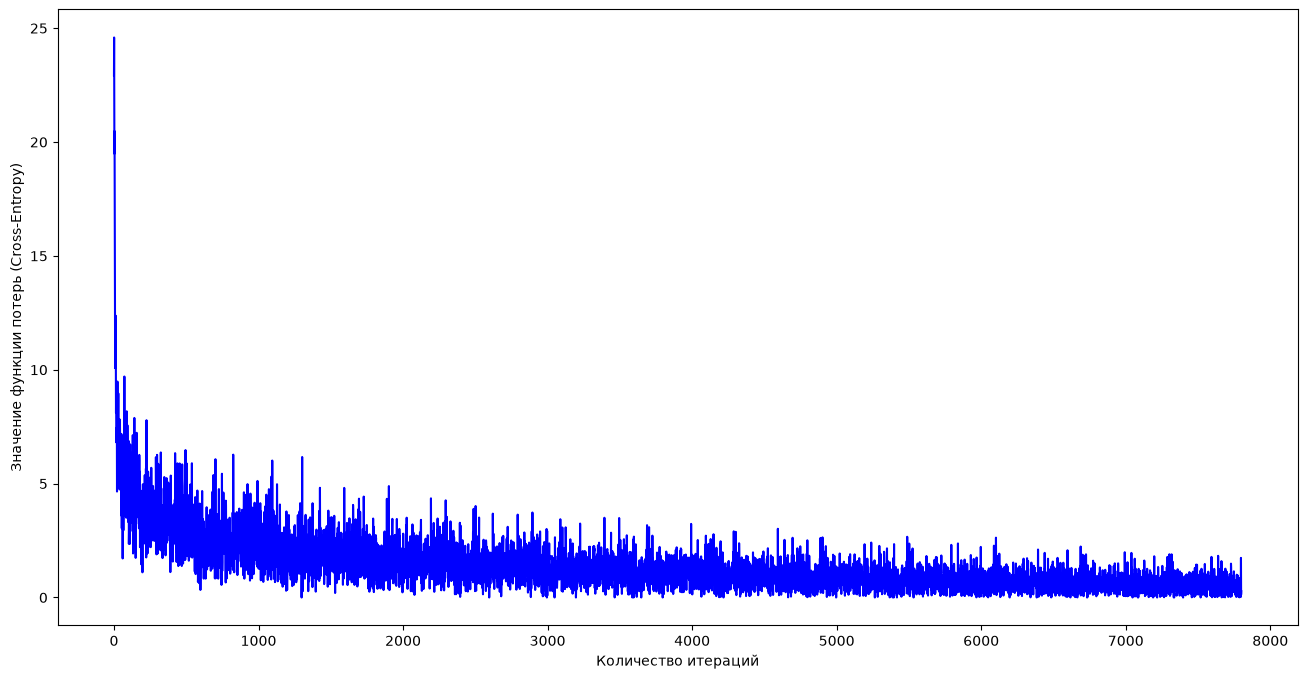

In [14]:
iterations = np.arange(train_iter).tolist()
plt.subplots(figsize=(16, 8))
plt.plot(iterations, train_loss, color="blue")
plt.xlabel("Количество итераций")
plt.ylabel("Значение функции потерь (Cross-Entropy)")

Text(0, 0.5, 'Значение функции потерь (Cross-Entropy)')

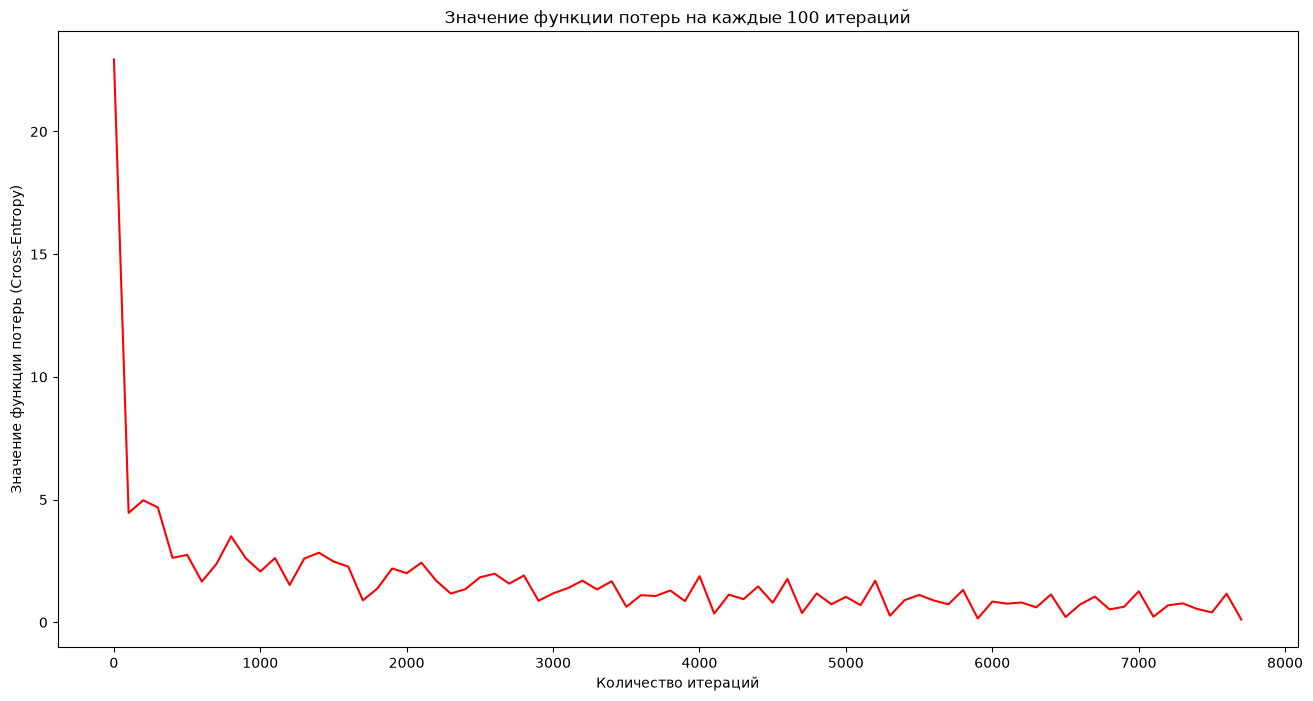

In [15]:
plt.subplots(figsize=(16, 8))
plt.plot(average_train_iter, average_train_loss, color="red")
plt.title("Значение функции потерь на каждые 100 итераций")
plt.xlabel("Количество итераций")
plt.ylabel("Значение функции потерь (Cross-Entropy)")

## 5. Сравнение с PyTorch

In [16]:
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

Опишем класс dataset для загрузки данных в модель

In [17]:
class dataset(Dataset):
    def __init__(self, path):
        super().__init__()
        self.data = np.loadtxt(path, delimiter=',', skiprows=1)

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        x = torch.tensor(self.data[index, 1:], dtype=torch.float32) / 255
        y = torch.tensor(self.data[index, 0], dtype=torch.long)
        return x, y
    

Проверим корректность методов

In [18]:
train_path = "datasets/mnist_train.csv"
torch_train_data = dataset(train_path)

test_path = "datasets/mnist_test.csv"
torch_test_data = dataset(test_path)

In [19]:
train_data.__len__()

60000

In [20]:
train_data.__getitem__(0)

array([  5.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
         0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
         0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
         0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
         0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
         0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
         0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
         0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
         0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
         0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
         0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
         0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
         0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
         0.,   0.,   0.,   0.,   0.,   0.,   0.,   

In [21]:
batch_size = 100
train_loader = DataLoader(torch_train_data, batch_size=batch_size, shuffle=False)       # Для корректности сравнения перемешивать датасет не будем
test_loader = DataLoader(torch_test_data, batch_size=batch_size, shuffle=False)

In [22]:
for x, y in train_loader:
    print(x.shape)
    print(y.shape)
    break

torch.Size([100, 784])
torch.Size([100])


Создадим в PyTorch модель с архитектурой, соответствующей нашей реализации MLP

In [23]:
class torch_MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(28*28, 512, bias=False),
            nn.ReLU(),
            nn.Linear(512, 256, bias=False),
            nn.ReLU(),
            nn.Linear(256, 10, bias=False)
        )

    def forward(self, x):
        logits = self.layers
        return logits(x)

In [24]:
torch_model = torch_MLP()
print(torch_model)

torch_MLP(
  (layers): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=False)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=256, bias=False)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=10, bias=False)
  )
)


In [25]:
torch_model.eval()
sample = torch.randn(1, 28*28)
torch_model(sample)

tensor([[ 0.1271,  0.0309, -0.0105, -0.0093, -0.0792,  0.0782,  0.0494, -0.1113,
          0.0350, -0.0246]], grad_fn=<MmBackward0>)

В собственной реализации в качестве оптимизатора используется градиентный спуск,  поэтому установим его и для данной модели

In [26]:
lr = 0.01
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(params=torch_model.parameters(), lr=lr)

Опишем функции для обучения и валидации модели

In [27]:
def train(model, loss_fn, optimizer, loader, train_iter, list_of_loss, average_train_iter, average_train_loss):
    model.train()

    for batch, (x, y) in enumerate(loader):
        train_iter += 1
        y_pred = model(x)
        loss = loss_fn(y_pred, y)

        if batch % 100 == 0:
            print(f"Batch №{batch}\tTrain loss: {loss.item()}")
            average_train_iter.append(train_iter)
            average_train_loss.append(loss.item())

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        list_of_loss.append(loss.item())

    return train_iter


def test(model, loss_fn, loader):
    model.eval()
    num_batches = len(loader)
    loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for x, y in loader:
            y_pred = model(x)
            loss += loss_fn(y_pred, y)
            correct += (y_pred.argmax(1) == y).sum().item()
            total += y.size(0)

    loss = loss / num_batches           # Средняя ошибка
    accuracy = correct / total
    print(f"Loss: {loss}\tAccuracy: {accuracy}\n")

    return loss

Обучим модель

In [28]:
epochs = 13

# Для анализа изменения ошибки
train_iter = 0
train_loss = list()
average_train_iter_torch = list()
average_train_loss_torch = list()

for i in range(epochs):
    print(f"Epoch: {i}")
    train_iter = train(torch_model, loss_fn, optimizer, train_loader, train_iter, train_loss, average_train_iter_torch, average_train_loss_torch)
    test(torch_model, loss_fn, test_loader)

Epoch: 0
Batch №0	Train loss: 2.295501708984375
Batch №100	Train loss: 2.250913619995117
Batch №200	Train loss: 2.2229056358337402
Batch №300	Train loss: 2.099257469177246
Batch №400	Train loss: 1.874137282371521
Batch №500	Train loss: 1.6774230003356934
Loss: 1.3009032011032104	Accuracy: 0.7429

Epoch: 1
Batch №0	Train loss: 1.2854913473129272
Batch №100	Train loss: 1.0081586837768555
Batch №200	Train loss: 1.0380568504333496
Batch №300	Train loss: 0.8671842217445374
Batch №400	Train loss: 0.5971726775169373
Batch №500	Train loss: 0.6584755778312683
Loss: 0.550682544708252	Accuracy: 0.8551

Epoch: 2
Batch №0	Train loss: 0.596215009689331
Batch №100	Train loss: 0.5123080611228943
Batch №200	Train loss: 0.6614572405815125
Batch №300	Train loss: 0.5565264225006104
Batch №400	Train loss: 0.384019136428833
Batch №500	Train loss: 0.4739840626716614
Loss: 0.41374924778938293	Accuracy: 0.8847

Epoch: 3
Batch №0	Train loss: 0.44294899702072144
Batch №100	Train loss: 0.4195294976234436
Batch №2

Text(0, 0.5, 'Значение функции потерь (Cross-Entropy)')

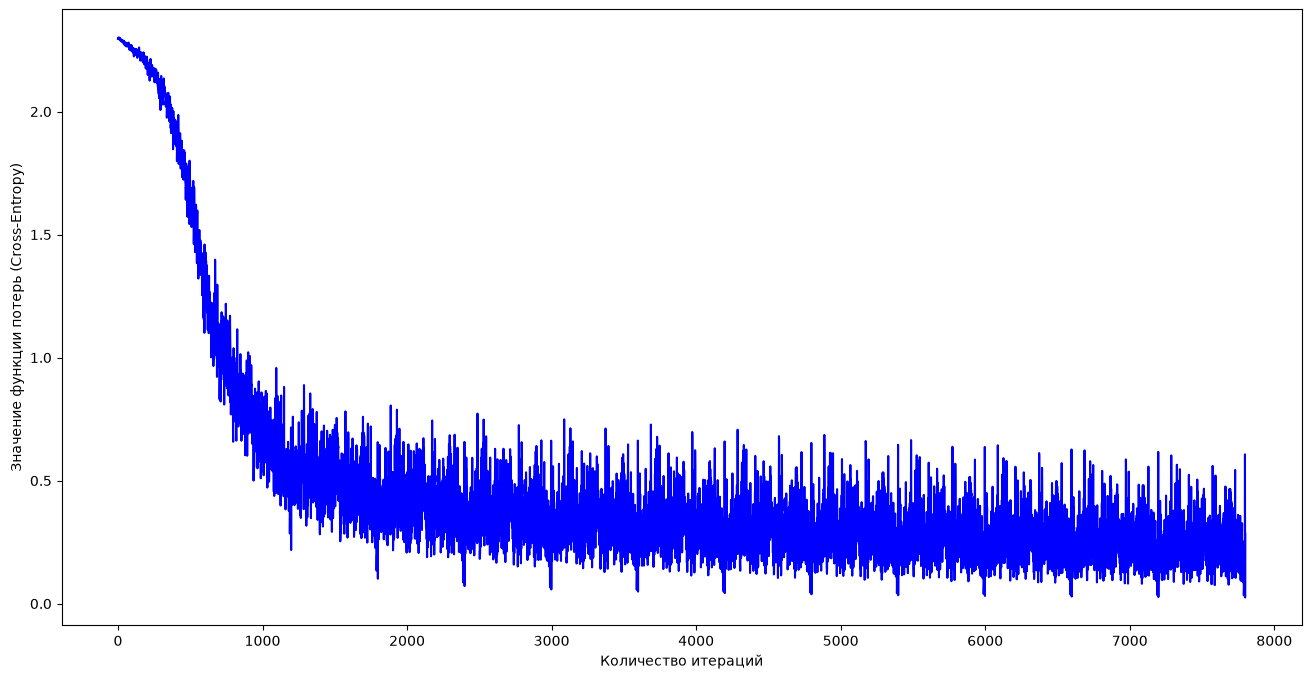

In [29]:
iterations = np.arange(train_iter).tolist()
plt.subplots(figsize=(16, 8))
plt.plot(iterations, train_loss, color="blue")
plt.xlabel("Количество итераций")
plt.ylabel("Значение функции потерь (Cross-Entropy)")

Text(0, 0.5, 'Значение функции потерь (Cross-Entropy)')

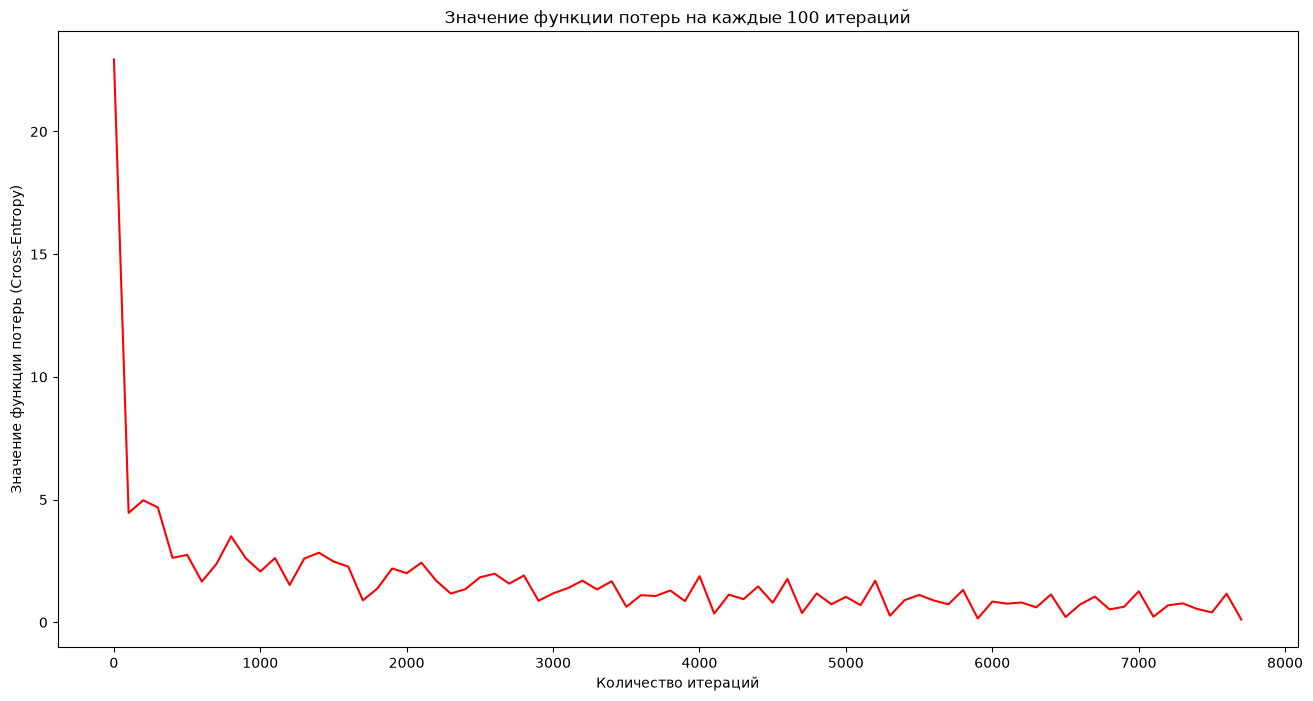

In [30]:
plt.subplots(figsize=(16, 8))
plt.plot(average_train_iter, average_train_loss, color="red")
plt.title("Значение функции потерь на каждые 100 итераций")
plt.xlabel("Количество итераций")
plt.ylabel("Значение функции потерь (Cross-Entropy)")

### Сравним, как изменялась ошибка каждой модели при обучении

[]

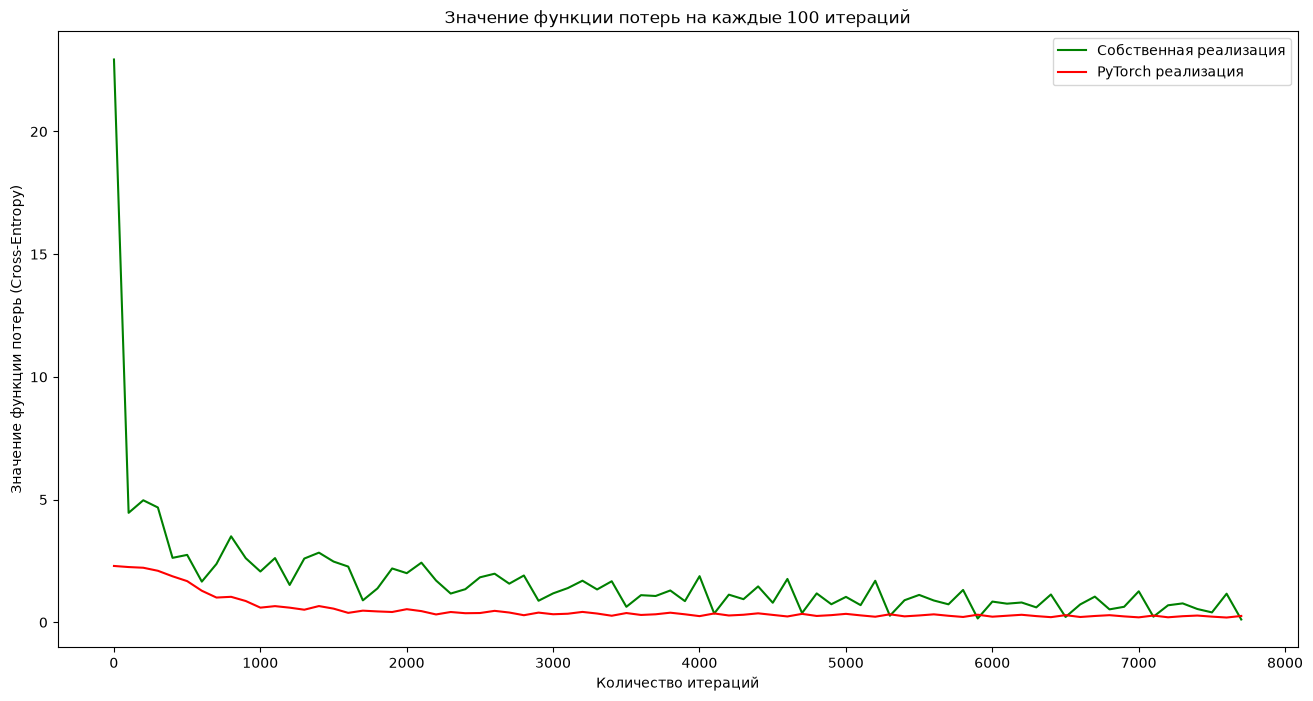

In [31]:
plt.subplots(figsize=(16, 8))
plt.plot(average_train_iter, average_train_loss, color="g", label="Собственная реализация")
plt.plot(average_train_iter_torch, average_train_loss_torch, color="red", label="PyTorch реализация")
plt.title("Значение функции потерь на каждые 100 итераций")
plt.xlabel("Количество итераций")
plt.ylabel("Значение функции потерь (Cross-Entropy)")
plt.legend()
plt.plot()

Можно заметить, что начальные значения функции потерь моделей существенно различаются. Одной из причин является различие в способах инициализации весов. В моей реализации веса генерируются из стандартного нормального распределения, тогда как PyTorch использует собственную схему инициализации по умолчанию. Это приводит к различным начальным значениям параметров и, как следствие, различным траекториям обучения моделей.

## 6. Сравнение качества моделей на тестовой выборке

In [32]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

batch_size = len(test_data)
labels = np.arange(0, 10)

### Получение предсказаний собственной модели

In [33]:
x_test, y_test = get_x_y(0, test_data, batch_size)
x_test = (x_test - min_value) / max_value                           # Нормализуем данные
predict = model.forward(x_test)
predict = model.Softmax(predict)

In [34]:
result = predict.argmax(1)

In [35]:
result

array([7, 2, 1, ..., 4, 5, 6], shape=(10000,))

Точность кастомной модели

In [36]:
print(f"Accuracy: {accuracy_score(y_test, result)}")

Accuracy: 0.9137


In [37]:
print(classification_report(y_test, result))

              precision    recall  f1-score   support

           0       0.96      0.96      0.96       980
           1       0.96      0.97      0.97      1135
           2       0.91      0.89      0.90      1032
           3       0.89      0.90      0.90      1010
           4       0.89      0.93      0.91       982
           5       0.84      0.91      0.87       892
           6       0.97      0.94      0.95       958
           7       0.92      0.92      0.92      1028
           8       0.90      0.85      0.88       974
           9       0.90      0.86      0.88      1009

    accuracy                           0.91     10000
   macro avg       0.91      0.91      0.91     10000
weighted avg       0.91      0.91      0.91     10000



Для более детального анализа результатов построим матрицу ошибок. Строки матрицы соответствуют истинным классам, столбцы — предсказанным. Значения на главной диагонали показывают количество правильных классификаций, остальные элементы — количество ошибочных предсказаний.

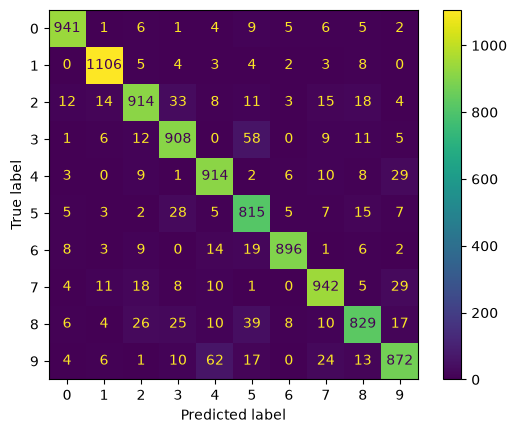

In [38]:
cm = confusion_matrix(y_test, result, labels=labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)    
disp.plot()

### Получение предсказаний модели на PyTorch

In [39]:
predict_loader = DataLoader(torch_test_data, batch_size=batch_size, shuffle=False)

torch_model.eval()
with torch.no_grad():
    for x, y in predict_loader:
        torch_predict = torch_model(x)

In [40]:
torch_predict.shape

torch.Size([10000, 10])

In [41]:
torch_predict = torch_predict.numpy()

In [42]:
torch_predict = torch_predict.argmax(1)

In [43]:
torch_predict

array([7, 2, 1, ..., 4, 5, 6], shape=(10000,))

In [44]:
print(f"Accuracy: {accuracy_score(y_test, torch_predict)}")

Accuracy: 0.9345


In [45]:
print(classification_report(y_test, torch_predict))

              precision    recall  f1-score   support

           0       0.94      0.98      0.96       980
           1       0.97      0.98      0.98      1135
           2       0.95      0.91      0.93      1032
           3       0.93      0.92      0.92      1010
           4       0.94      0.93      0.93       982
           5       0.91      0.91      0.91       892
           6       0.94      0.95      0.95       958
           7       0.95      0.93      0.94      1028
           8       0.90      0.91      0.91       974
           9       0.91      0.93      0.92      1009

    accuracy                           0.93     10000
   macro avg       0.93      0.93      0.93     10000
weighted avg       0.93      0.93      0.93     10000



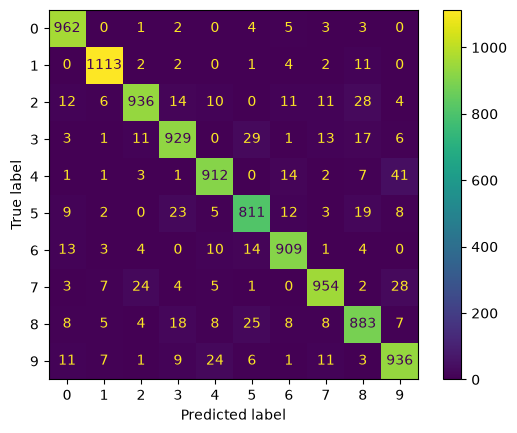

In [46]:
cm = confusion_matrix(y_test, torch_predict, labels=labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)    
disp.plot()

Помимо точности классификации, сравним значения функции потерь Cross-Entropy. Для кастомной реализации значение Loss составило 1.6389, тогда как для модели PyTorch — 0.2296.

Несмотря на относительно небольшую разницу в Accuracy, значения функции потерь существенно отличаются. Это связано с тем, что Cross-Entropy учитывает не только правильность предсказанного класса, но и вероятностное распределение предсказаний модели. Таким образом, полученные результаты показывают, что собственная реализация, несмотря на достаточно высокую точность классификации, менее уверенно распределяет вероятности относительно истинных классов.

## 7. Заключение

В рамках данной работы был разработан собственный инструмент для создания и обучения полносвязных нейронных сетей (MLP). Основной целью реализации было упрощение процесса конфигурирования модели за счёт автоматического определения размерностей слоёв и формирования соответствующих матриц весов.

Для проверки работоспособности реализации была решена задача классификации рукописных цифр из набора данных MNIST. Полученная модель успешно прошла обучение и продемонстрировала точность классификации 91.37% на тестовой выборке.

Дополнительно была реализована аналогичная архитектура с использованием PyTorch, что позволило сравнить результаты работы двух моделей. Точность модели на PyTorch составила 93.45%, что на 2.08 % выше результата собственной реализации.

Несмотря на небольшую разницу в показателе Accuracy, обе модели продемонстрировали близкое качество классификации. Полученные результаты показывают, что разработанная реализация способна успешно решать задачу классификации MNIST и демонстрирует работоспособность реализованных механизмов прямого и обратного распространения ошибки.

Таким образом, поставленная практическая цель была достигнута: удалось создать инструмент, позволяющий конфигурировать архитектуру MLP через простой программный интерфейс и обучать полученную модель без необходимости вручную определять размерности отдельных слоёв.

В дальнейшем реализацию можно расширить, добавив новые функции активации, функции потерь и алгоритмы оптимизации, а также улучшив производительность вычислений и механизмы инициализации весов.